# Final Project: Data Analytics with Python

My final project in Python will be dealing with LA crime statistics, and I will be showing the steps I took to clean, manipulate, and visualize the data.



# Imports/Starting Point
First I Start with imports, importing all the data libraries i need, even if i might not use them at all. Its better to have it and not need it.

In [107]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('LA crime.csv')
pd.set_option('display.max_columns', None)
df

KeyboardInterrupt: 

# ***Cleaning data***

Cleaning data has multiple steps you may need to take depending on the type of data. Cleaning data may include:



*   Finding empty values and adressing them
*   Finding duplicates


*   Taking note of outliers and figuring out to either keep them or get rid of them.
*   Fixing incorrect data types

( an Intenger might be mistaken for a string and vice
versa)


*   Standardizing text(making text start with a capital)
*   Fixing similar values(changing it so that "yes" "Y" "YES" and "Yes" mean the same thing. or change them all to be the same thing






In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  object 
 2   DATE OCC        1004894 non-null  object 
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  object 
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  object 
 10  Mocodes         853296 non-null   object 
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   object 
 13  Vict Descent    860251 non-null   object 
 14  Premis Cd       1004878 non-null  float64
 15  Premis Desc     1004306 non-null  object 
 16  Weapon Used Cd  327216 non-null   fl

In [ ]:
df.duplicated().sum()
# Here it shows there are NO duplicates in the dataset

np.int64(0)

In [ ]:
df.isna().sum()
# Here it shows that alot of columns dont have empty cells but when they do it is a LOT of empty cells

#So im going to drop the columns that are mostly empty like CRM CD 2, CRM CD 3, and CRM CD 4

,0
DR_NO,0
Date Rptd,0
DATE OCC,0
TIME OCC,0
AREA,0
AREA NAME,0
Rpt Dist No,0
Part 1-2,0
Crm Cd,0
Crm Cd Desc,0


In [ ]:
# Here im dropping the columns that are mostly empty
df = df.drop(columns=['Crm Cd 2', 'Crm Cd 3', "Crm Cd 4"])
df.isna().sum()

,0
DR_NO,0
Date Rptd,0
DATE OCC,0
TIME OCC,0
AREA,0
AREA NAME,0
Rpt Dist No,0
Part 1-2,0
Crm Cd,0
Crm Cd Desc,0


In [ ]:
# Finding negatives

df[df["Vict Age"] < 0].sort_values(by="Vict Age", ascending=True)
# Since the ages are all in the toddler age range we will just get rid of them.
df = df[df["Vict Age"] > 0]

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Mocodes,Vict Age,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Status Desc,Crm Cd 1,LOCATION,Cross Street,LAT,LON


In [ ]:
# Fixing the columns to be date oriented
df["DATE OCC"] = pd.to_datetime(df["DATE OCC"])
df["Date Rptd"] = pd.to_datetime(df["Date Rptd"])
# Checking the change
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 735579 entries, 0 to 1004892
Data columns (total 25 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   DR_NO           735579 non-null  int64         
 1   Date Rptd       735579 non-null  datetime64[ns]
 2   DATE OCC        735579 non-null  datetime64[ns]
 3   TIME OCC        735579 non-null  int64         
 4   AREA            735579 non-null  int64         
 5   AREA NAME       735579 non-null  object        
 6   Rpt Dist No     735579 non-null  int64         
 7   Part 1-2        735579 non-null  int64         
 8   Crm Cd          735579 non-null  int64         
 9   Crm Cd Desc     735579 non-null  object        
 10  Mocodes         729904 non-null  object        
 11  Vict Age        735579 non-null  int64         
 12  Vict Sex        735547 non-null  object        
 13  Vict Descent    735547 non-null  object        
 14  Premis Cd       735578 non-null  float64

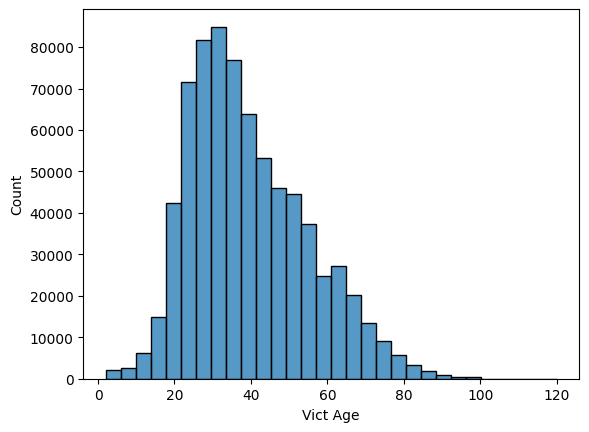

In [ ]:
# Here I will make a quick scatter plot based on the ages of people
# finding if there is any outliers to get rid off
sns.histplot(
    data=df, x="Vict Age", bins=30

    )
plt.show()
# Looks fine so we can leave it alone.

In [ ]:
# Checking empty values once again.
# Im deciding to keep the "Weapon Used Cd" and "Weapon Desc" as well as "Cross Street"
# as it will give us some helpful insight enough though most of it is missing.
# Although i will get rid of the Mocodes Column entirly as it wont help out in this analysis.
df.isna().sum()

,0
DR_NO,0
Date Rptd,0
DATE OCC,0
TIME OCC,0
AREA,0
AREA NAME,0
Rpt Dist No,0
Part 1-2,0
Crm Cd,0
Crm Cd Desc,0


In [ ]:
#getting rid of Mocodes
df = df.drop(columns=["Mocodes"])


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 735579 entries, 0 to 1004892
Data columns (total 24 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   DR_NO           735579 non-null  int64         
 1   Date Rptd       735579 non-null  datetime64[ns]
 2   DATE OCC        735579 non-null  datetime64[ns]
 3   TIME OCC        735579 non-null  int64         
 4   AREA            735579 non-null  int64         
 5   AREA NAME       735579 non-null  object        
 6   Rpt Dist No     735579 non-null  int64         
 7   Part 1-2        735579 non-null  int64         
 8   Crm Cd          735579 non-null  int64         
 9   Crm Cd Desc     735579 non-null  object        
 10  Vict Age        735579 non-null  int64         
 11  Vict Sex        735547 non-null  object        
 12  Vict Descent    735547 non-null  object        
 13  Premis Cd       735578 non-null  float64       
 14  Premis Desc     735350 non-null  object 

In [ ]:
#Getting rid of all the null in these columns
df = df.dropna(subset=[
    "Vict Sex",
    "Vict Descent",
    "Premis Cd",
    "Premis Desc",
    "Crm Cd 1",
    "Weapon Used Cd",
    "Weapon Desc",
    "Cross Street"
])
df.isna().sum()


,0
DR_NO,0
Date Rptd,0
DATE OCC,0
TIME OCC,0
AREA,0
AREA NAME,0
Rpt Dist No,0
Part 1-2,0
Crm Cd,0
Crm Cd Desc,0


In [ ]:
# With the amount of cleaning we went from 1 million rows of data, to a tiny 70.5k rows of data. Now lets start data manipulation.
df

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Vict Age,Vict Sex,Vict Descent,Premis Cd,Premis Desc,Weapon Used Cd,Weapon Desc,Status,Status Desc,Crm Cd 1,LOCATION,Cross Street,LAT,LON
1,201516622,2020-10-21,2020-10-18,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",32,M,H,102.0,SIDEWALK,200.0,KNIFE WITH BLADE 6INCHES OR LESS,IC,Invest Cont,230.0,ATOLL AV,N GAULT,34.1993,-118.4203
16,201820230,2020-11-08,2020-11-08,730,18,Southeast,1844,2,626,INTIMATE PARTNER - SIMPLE ASSAULT,26,F,B,101.0,STREET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,626.0,108TH ST,AVALON AV,33.9383,-118.2652
47,201810632,2020-05-04,2020-05-04,1530,18,Southeast,1804,2,624,BATTERY - SIMPLE ASSAULT,18,F,W,102.0,SIDEWALK,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,624.0,MANCHESTER AV,AVALON BL,33.9602,-118.2651
63,201817027,2020-09-10,2020-09-10,2145,18,Southeast,1827,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",53,F,H,103.0,ALLEY,500.0,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,230.0,95TH ST,ANZAC,33.9506,-118.2375
73,201817357,2020-09-12,2020-09-12,30,18,Southeast,1871,2,930,CRIMINAL THREATS - NO WEAPON DISPLAYED,21,F,B,101.0,STREET,511.0,VERBAL THREAT,IC,Invest Cont,930.0,ROSECRANS,VERMONT,33.9019,-118.2916
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1004861,240507700,2024-04-07,2024-04-07,1700,5,Harbor,583,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",32,M,W,101.0,STREET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,230.0,25TH,WESTERN,33.7230,-118.3129
1004866,241807402,2024-03-12,2024-03-12,630,18,Southeast,1841,2,624,BATTERY - SIMPLE ASSAULT,33,M,H,101.0,STREET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,624.0,106TH ST,BROADWAY,33.9367,-118.2871
1004877,240405919,2024-02-27,2024-02-26,1545,4,Hollenbeck,422,1,761,BRANDISH WEAPON,18,M,H,102.0,SIDEWALK,101.0,REVOLVER,IC,Invest Cont,761.0,THOMAS ST,BALDWIN ST,34.0703,-118.2052
1004884,242004546,2024-01-16,2024-01-16,1510,20,Olympic,2013,2,624,BATTERY - SIMPLE ASSAULT,80,F,O,124.0,BUS STOP,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,624.0,HOBART BL,3RD ST,34.0690,-118.3054


#***Data Manipulation***

 Data manipulation is changing the dataset by either making new columns based of other columns, filtering the dataset, or even merging columns. Data manipulation can come in many different forms and will depend on what is in your dataset.

In [110]:
# Showing crime from 2020-2024 from oldest(2020) to newest(2024)
Old2NewCrimedf = df [
  (df["DATE OCC"].dt.year >=2020) &
  (df["DATE OCC"].dt.year <=2024)
]

Old2NewCrimedf.sort_values(by="DATE OCC", ascending=True)

AttributeError: Can only use .dt accessor with datetimelike values

In [112]:
#New column tosort by year later on
df["Year"] = pd.to_datetime(df["DATE OCC"]).dt.year

/tmp/ipykernel_959/1656984236.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Year"] = pd.to_datetime(df["DATE OCC"]).dt.year


In [ ]:
# Crimes most common to happen
common_crimes = df.groupby("Crm Cd Desc").size().reset_index(name="Crime Count")

common_crimes = common_crimes.sort_values(
    by="Crime Count",
    ascending=False
)

common_crimes.head(10)

,Crm Cd Desc,Crime Count
2,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",19008
4,BATTERY - SIMPLE ASSAULT,14568
64,ROBBERY,11772
42,INTIMATE PARTNER - SIMPLE ASSAULT,6003
10,BRANDISH WEAPON,3390
3,ATTEMPTED ROBBERY,2073
26,CRIMINAL THREATS - NO WEAPON DISPLAYED,1975
41,INTIMATE PARTNER - AGGRAVATED ASSAULT,1849
85,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",952
7,BATTERY WITH SEXUAL CONTACT,951


In [ ]:
# Where crime most happens

df["AREA NAME"].value_counts()


,count
AREA NAME,
77th Street,7627
Central,7272
Newton,5847
Southeast,5569
Southwest,4751
Rampart,4703
Hollywood,4431
Olympic,4360
Hollenbeck,2506


In [ ]:
# Most common Victim Age
df["Vict Age"].value_counts(ascending=False)

,count
Vict Age,
30,2121
28,2039
26,2019
27,1987
25,1972
29,1958
31,1939
33,1868
32,1849


In [108]:
 # What age deals with what crime the most?
 crime_age = df.groupby(
    ["Crm Cd Desc", "Vict Age"]
).size().reset_index(name="Count")

crime_age = crime_age.sort_values(
    ["Crm Cd Desc", "Count"],
    ascending=[True, False]
)

most_common_age = crime_age.groupby("Crm Cd Desc").first()

most_common_age

,Vict Age,Count
Crm Cd Desc,,
ARSON,0,1102
ASSAULT WITH DEADLY WEAPON ON POLICE OFFICER,0,819
"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",0,2027
ATTEMPTED ROBBERY,0,627
BATTERY - SIMPLE ASSAULT,30,1929
BATTERY ON A FIREFIGHTER,0,83
BATTERY POLICE (SIMPLE),0,1863
BATTERY WITH SEXUAL CONTACT,16,164
"BEASTIALITY, CRIME AGAINST NATURE SEXUAL ASSLT WITH ANIM",0,5


In [ ]:
# Everyone in LA is getting assulted with a deadly weapon
crime_age.sort_values(by="Count", ascending=False).head(10)

,Crm Cd Desc,Vict Age,Count
104,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",30,623
100,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",26,567
102,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",28,554
101,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",27,553
105,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",31,530
103,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",29,521
109,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",35,520
106,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",32,515
107,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",33,508
99,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",25,503


In [113]:
crime_pivot = df.pivot_table(
    index="Crm Cd Desc",
    columns="Year",
    values="DR_NO",
    aggfunc="count",
    fill_value=0
)
crime_pivot

Year,2020,2021,2022,2023,2024
Crm Cd Desc,,,,,
ARSON,665,627,531,577,165
ASSAULT WITH DEADLY WEAPON ON POLICE OFFICER,397,217,227,180,57
"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",11525,12739,12870,12694,3695
ATTEMPTED ROBBERY,1123,1147,1165,1077,326
BATTERY - SIMPLE ASSAULT,16331,16199,18059,18832,5400
BATTERY ON A FIREFIGHTER,46,57,66,72,16
BATTERY POLICE (SIMPLE),618,627,564,560,196
BATTERY WITH SEXUAL CONTACT,963,932,1035,955,277
"BEASTIALITY, CRIME AGAINST NATURE SEXUAL ASSLT WITH ANIM",0,3,3,3,0


#***Visualizing the data***
Visualizing the data  is done by using libraries like matpltlib or seaborn, I will be using seaborn as I find it easier and more friendly to use

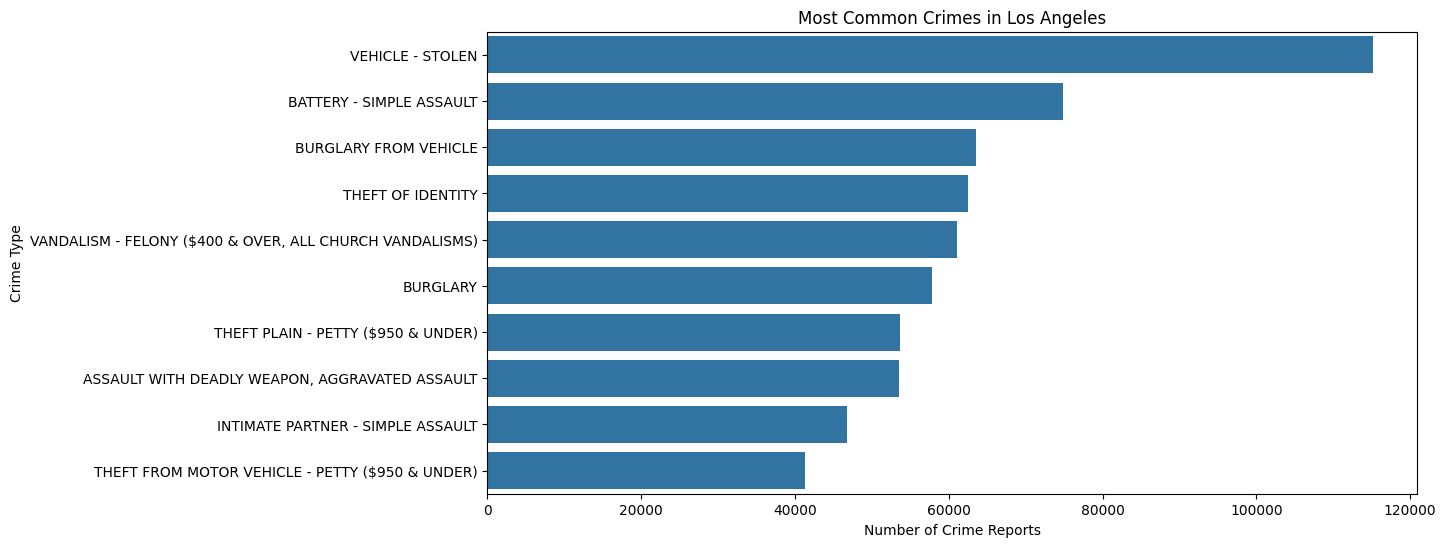

In [117]:
# Using the bar graph to compare the crimes from 2020-2024, showing what dominates as the most common crime.
top_crimes = df["Crm Cd Desc"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_crimes.values, y=top_crimes.index)

plt.title("Most Common Crimes in Los Angeles")
plt.xlabel("Number of Crime Reports")
plt.ylabel("Crime Type")


plt.show()

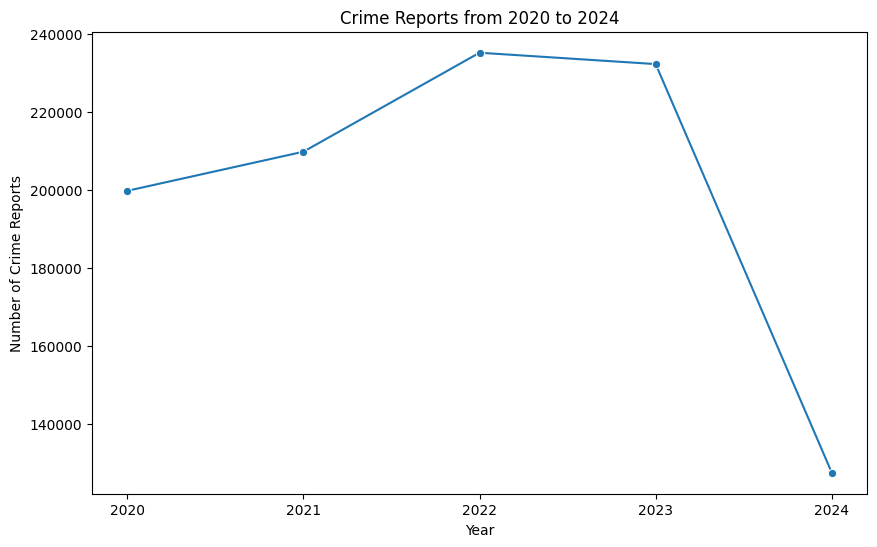

In [122]:

df["Year"] = df["DATE OCC"].dt.year

yearly_crimes = df["Year"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

sns.lineplot(x=yearly_crimes.index, y=yearly_crimes.values, marker="o")

plt.title("Crime Reports from 2020 to 2024")
plt.xlabel("Year")
plt.ylabel("Number of Crime Reports")

plt.xticks([2020, 2021, 2022, 2023, 2024])

plt.show()


# There is a GIANT dip from 2023 crime reports to 2024 crime reports.
 This may be due to the massive data I cleaned up at the start. Which may have remove a LOT of 2024 crime reports as it had empty values that were better to get rid of than keep.

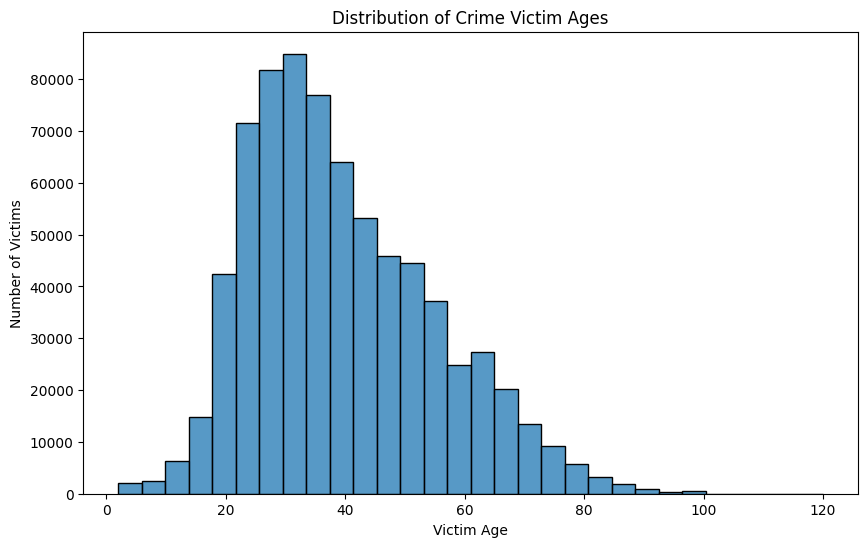

In [123]:
vic_ages = df.loc[df["Vict Age"] > 0, "Vict Age"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(vic_ages, bins=30)

plt.title("Distribution of Crime Victim Ages")
plt.xlabel("Victim Age")
plt.ylabel("Number of Victims")


plt.show()

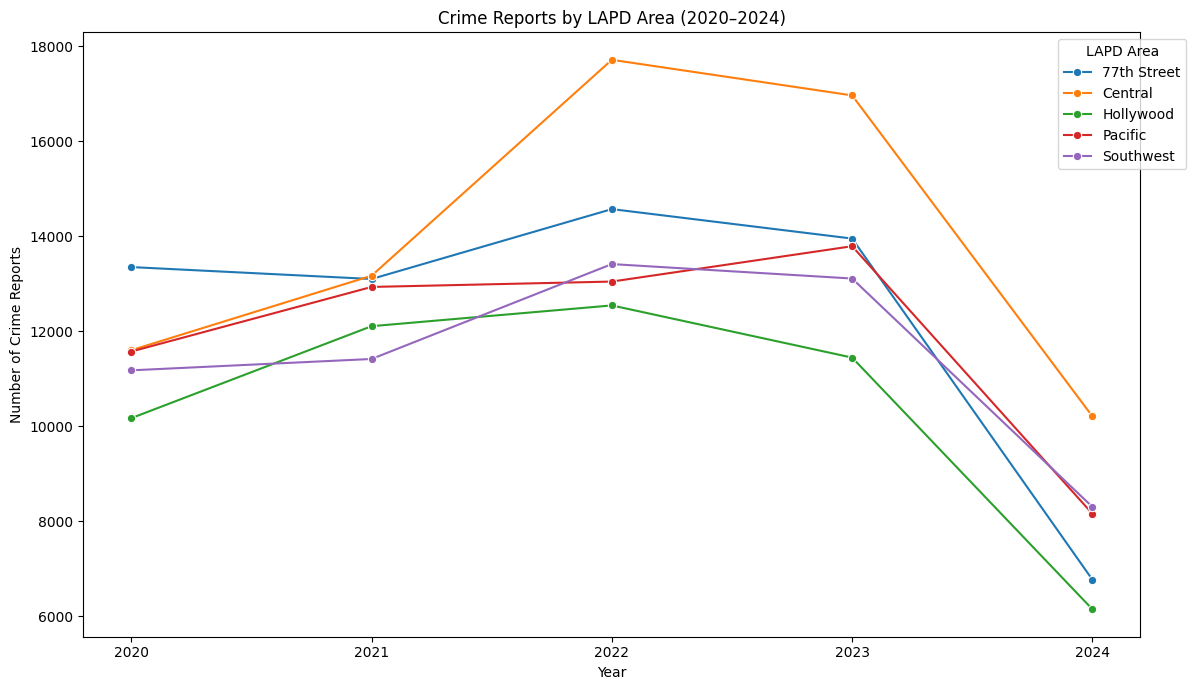

In [125]:
# Group crimes by area and year
area_year = df.groupby(
    ["AREA NAME", "Year"]
).size().reset_index(name="Crime Count")

# Find the top 5 areas overall
top_5 = (
    area_year.groupby("AREA NAME")["Crime Count"]
    .sum()
    .nlargest(5)
    .index
)

# Filter for those 5 areas
area_year_top5 = area_year[
    area_year["AREA NAME"].isin(top_5)
]

# Create line graph
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=area_year_top5,
    x="Year",
    y="Crime Count",
    hue="AREA NAME",
    marker="o"
)

plt.title("Crime Reports by LAPD Area (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Number of Crime Reports")
plt.xticks([2020, 2021, 2022, 2023, 2024])
plt.legend(title="LAPD Area", bbox_to_anchor=(1.05, 1))
plt.tight_layout()


plt.show()

# The graph above shows the top 5 areas with the most reports within LA. Showing the changes of how many reports in each in

#***Stat Analysist***
The Stat analyticals is based on the ages of the victims of the crimes

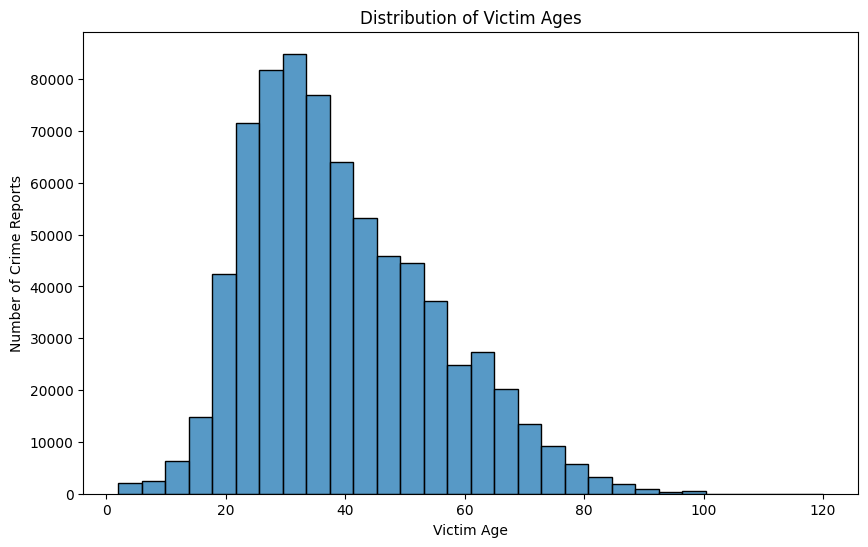

In [129]:
#Distribution
distages = df.loc[df["Vict Age"] > 0, "Vict Age"].dropna()
plt.figure(figsize=(10, 6))

sns.histplot(distages, bins=30)

plt.title("Distribution of Victim Ages")
plt.xlabel("Victim Age")
plt.ylabel("Number of Crime Reports")


plt.show()

In [130]:
df["DATE OCC"] = pd.to_datetime(df["DATE OCC"], errors="coerce")
df["Year"] = df["DATE OCC"].dt.year

yearly_stats = df.groupby("Year").agg(
    Total_Crimes=("DR_NO", "count"),
    Average_Victim_Age=("Vict Age", "mean")
)

print(yearly_stats.loc[2020:2024])

      Total_Crimes  Average_Victim_Age
Year                                  
2020        199847           30.065730
2021        209876           30.072629
2022        235259           30.018469
2023        232345           28.766076
2024        127567           23.472450


In [135]:
statages = df.loc[df["Vict Age"] > 0, "Vict Age"].dropna()

# Descriptive statistics
print("Mean victim age:", statages.mean())
print("Median victim age:", statages.median())
print("Mode victim age:", statages.mode().iloc[0])
print("Standard deviation:", statages.std())
print("Minimum age:", statages.min())
print("Maximum age:", statages.max())

Mean victim age: 39.50674774565342
Median victim age: 37.0
Mode victim age: 30
Standard deviation: 15.570936506367238
Minimum age: 2
Maximum age: 120


#END of Final Project: Data Analytics with Python